# 07 — Findings for the team: the `d100k` run

**Preliminary — for discussion within the team, before the analysis chapter.**

The `d100k` run (`20261018T122536Z`; S19, P8): 99,996 floor speeches, 1,923 per
Congress × party × chamber, 107th–119th Congress (2001–2025), scored for ideology
(−1 liberal … +1 conservative) and tone (0 neutral … 1 hostile) by
DeepSeek-V4.1-Flash-1017 alone, thinking mode. Each speech also carries a speech type
and, for policy debate, a topic (label run `20261017T182223Z`, L1–L8).

Two frames are loaded below:

- `everything` — every scored speech.
- `df` — substantive speech only: procedural and ceremonial speeches left out **by
  their label** (A3). This is the frame the trend analysis and the DW-NOMINATE
  validation (A5) use.

Four parts:

- **Part I — Bird's-eye view:** how far apart the parties are (1), which party moved (2),
  and whether the scores agree with DW-NOMINATE (3).
- **Part II — Polarization in depth:** presidential terms (4); newer and younger members (5).
- **Part III — Topics:** how much each topic polarized (6); a deep dive into the three
  most polarized topic blocks (7).
- **Part IV — Hostility:** has the tone become more hostile (8).

Everything after section 3 uses substantive speech (`df`).

Rules as in notebooks 04–06: **House and Senate are never pooled**, **every interval
is clustered by member**, and the **2016-09-10 source break** is marked at the 114th
Congress. Logic lives in `code/src/analysis.py` and `plots.py` (tested); this notebook
only calls it. Figures go to `results/plots/findings_*`, tables to
`results/metrics/findings_*`. No API calls.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT / "code"))

import matplotlib.pyplot as plt
import pandas as pd

from src.analysis import (
    AGE_GROUPS,
    TENURE_GROUPS,
    add_background,
    attach_labels,
    cell_means,
    gap_trend,
    load_scored_run,
    member_background,
    party_gap,
    relative_to_cell,
    substantive,
    toward_party,
    trend,
    within_cell_ols,
)
from src.config import (
    EXCLUDED_SPEECH_TYPES,
    METRICS_DIR,
    SCORES_DIR,
    SOURCE_BREAK_CONGRESS,
    TOPIC_BLOCKS,
    VALIDATION_HEADLINE,
)
from src.label_eval import label_shares
from src.labeling import BLOCK_OF_TOPIC
from src.plots import (
    TOPIC_BLOCK_PALETTE,
    plot_gap,
    plot_gap_by_group,
    plot_gap_trends,
    plot_group_means,
    plot_label_shares,
    plot_party_positions,
    plot_party_positions_by_group,
    plot_validation,
    save_figure,
)
from src.runs import run_models
from src.validation_design import (
    change_statistics,
    congress_changes,
    design_row,
    unit_table,
    validation_speeches,
    within_cell,
)

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 60)

RUN = "20261018T122536Z"        # d100k: 99,996 speeches, DeepSeek alone (S19)
LABEL_RUN = "20261017T182223Z"  # speech type and topic (L1-L8)

everything = attach_labels(load_scored_run(RUN), LABEL_RUN).dropna(subset=["ideology"])
df = substantive(everything)    # A3: procedural and ceremonial left out by label
(MODEL,) = run_models(SCORES_DIR, RUN)
print(f"Model {MODEL}: {len(everything):,} scored speeches; {len(df):,} substantive "
      f"(left out: {', '.join(EXCLUDED_SPEECH_TYPES)} and the unlabelled)")

Model deepseek-flash: 99,993 scored speeches; 71,121 substantive (left out: procedural, ceremonial and the unlabelled)


In [2]:
def with_ci(table, value="mean", digits=2):
    """'0.46 [0.35, 0.57]' -- a value with its 95% interval."""
    return table.apply(
        lambda r: f"{r[value]:+.{digits}f} [{r['ci_low']:+.{digits}f}, {r['ci_high']:+.{digits}f}]",
        axis=1,
    )


def span_ci(table, digits=2):
    """The change over the span with its interval: the slope's, times the span."""
    span = table["span"].map(lambda s: int(s.split("-")[1]) - int(s.split("-")[0]))
    return table.assign(ci_low=table["ci_low"] * span, ci_high=table["ci_high"] * span).pipe(
        with_ci, "change_over_span", digits
    )


def fit_table(fit, names):
    """`within_cell_ols` output as coefficient [95% interval] and p, one column per term."""
    shown = fit.assign(
        term=fit["term"].map(names),
        coef_ci=with_ci(fit, "coef", digits=3),
        p=fit["p"].map(lambda p: f"{p:.2g}"),
    )
    return shown.pivot(index=["chamber", "party"], columns="term", values=["coef_ci", "p"])

# Part I — Bird's-eye view

## 1. How far apart are the parties?

The party gap per Congress, Republican minus Democratic mean ideology, on
substantive speech: procedural and ceremonial speeches left out by their label (A3).
Those speeches sit near 0.0 for both parties, so keeping them would shrink the gap,
and shrink it more after 2016 as House ceremonial speeches grow (notebook 06,
section 1).

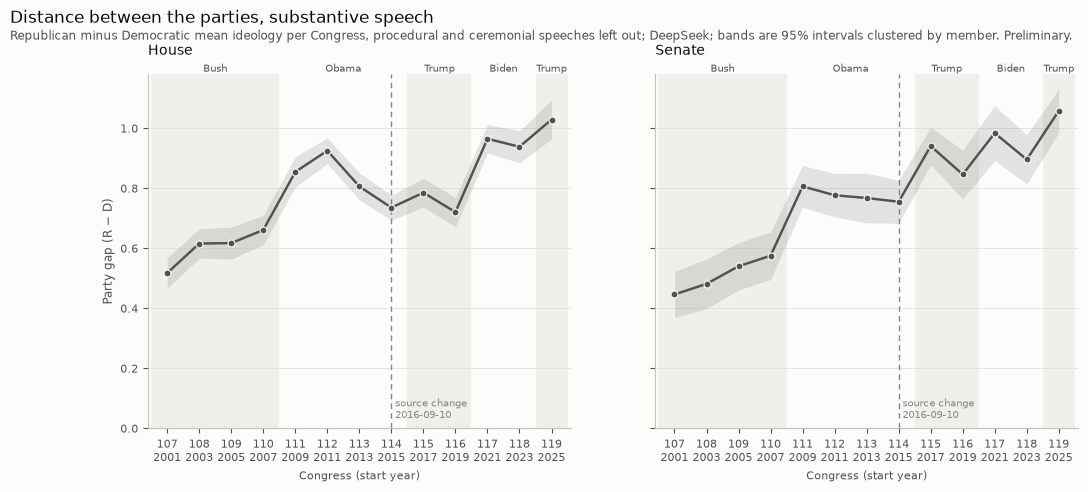

Party gap (R − D) with 95% interval, and speeches per party (fewest of the two):


gap_ci                           n      
chamber                             H                     S     H     S
congress_number                                                        
107              +0.52 [+0.47, +0.57]  +0.45 [+0.37, +0.52]  1409  1186
108              +0.62 [+0.57, +0.66]  +0.48 [+0.40, +0.56]  1396  1125
109              +0.62 [+0.56, +0.67]  +0.54 [+0.46, +0.62]  1439  1074
110              +0.66 [+0.61, +0.71]  +0.58 [+0.50, +0.65]  1484  1147
111              +0.85 [+0.80, +0.91]  +0.81 [+0.74, +0.88]  1436  1134
112              +0.93 [+0.88, +0.97]  +0.78 [+0.70, +0.85]  1507  1082
113              +0.81 [+0.76, +0.85]  +0.77 [+0.69, +0.85]  1538  1131
114              +0.74 [+0.69, +0.78]  +0.76 [+0.68, +0.83]  1409  1026
115              +0.79 [+0.74, +0.83]  +0.94 [+0.88, +1.00]  1281  1093
116              +0.72 [+0.67, +0.77]  +0.85 [+0.77, +0.93]  1305  1111
117              +0.97 [+0.92, +1.01]  +0.98 [+0.89, +1.08]  1376  1118
118              +0.94 [+0.89, +0.99]  +0.90 [+0.81, +0.98]  1349  1118
119              +1.03 [+0.96, +1.09]  +1.06 [+0.99, +1.13]  1222  1025

In [3]:
cells = cell_means(df)
gaps = party_gap(cells)
fig = plot_gap(
    gaps,
    "Distance between the parties, substantive speech",
    subtitle="Republican minus Democratic mean ideology per Congress, procedural and ceremonial speeches left out; DeepSeek; bands are 95% intervals clustered by member. Preliminary.",
)
save_figure(fig, "findings_party_gap")
plt.show()

print("Party gap (R − D) with 95% interval, and speeches per party (fewest of the two):")
n_min = cells.groupby(["congress_number", "chamber"])["n"].min().rename("n")
shown = gaps.assign(gap_ci=with_ci(gaps, "gap")).merge(n_min.reset_index(), on=["congress_number", "chamber"])
shown.pivot(index="congress_number", columns="chamber", values=["gap_ci", "n"])

**Reading it.** **The gap roughly doubles in both chambers**: House 0.52 [0.47, 0.57]
in the 107th Congress → 1.03 [0.96, 1.09] in the 119th, Senate 0.45 [0.37, 0.52] →
1.06 [0.99, 1.13]. Every point rests on 1,000–1,500 substantive speeches per party.

It does not rise in a straight line but in steps:

- **2009 (111th), both chambers.** House 0.66 → 0.85, Senate 0.58 → 0.81, at the start
  of the Obama presidency. This step lies inside the Stanford-only years, so the source
  change cannot explain it.
- **House: a dip, then a second step in 2021.** After a peak of 0.93 in the 112th the
  House gap falls back to 0.72–0.81 (113th–116th), then jumps to 0.97 in the 117th and
  stays at 0.94–1.03.
- **Senate: a second step in 2017.** From about 0.77 (111th–114th) to 0.94 in the 115th,
  then 0.85–1.06. This step **coincides with the source change and with Trump's first
  term**, so this plot alone cannot separate the two (notebook 05, section 5, finds no
  sign that govinfo pushes scores outward).

The figure shows distance only. Which party moved is the next question.

## 2. Which party moved?

Each party's mean position per Congress, on the same substantive speeches as section 1:
the gap above is the distance between these two lines.

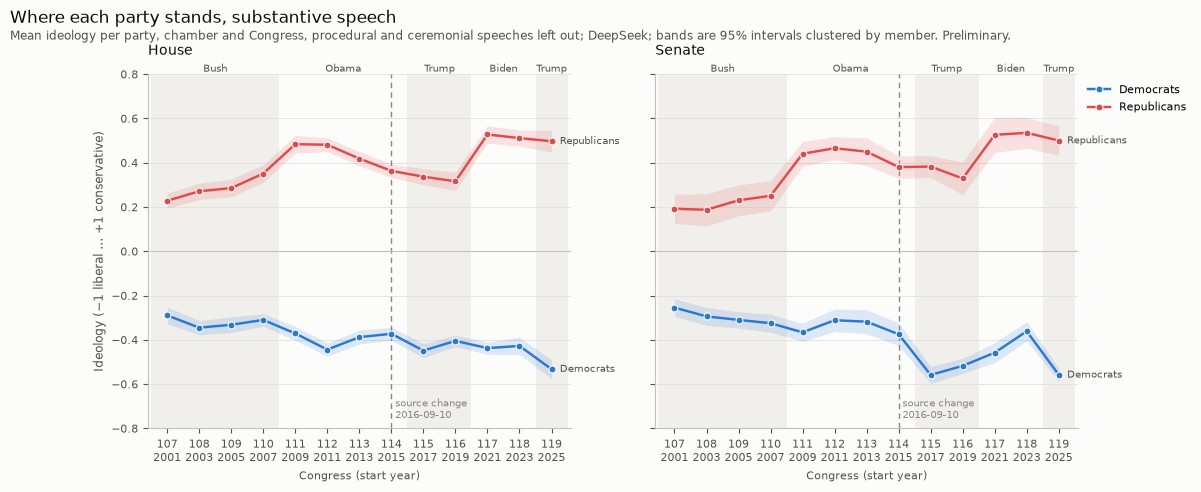

Each party's mean position with 95% interval:


cell,H · D,H · R,S · D,S · R
congress_number,,,,
107,"-0.29 [-0.33, -0.25]","+0.23 [+0.19, +0.26]","-0.25 [-0.29, -0.22]","+0.19 [+0.13, +0.26]"
108,"-0.34 [-0.38, -0.31]","+0.27 [+0.23, +0.31]","-0.29 [-0.33, -0.25]","+0.19 [+0.12, +0.26]"
109,"-0.33 [-0.37, -0.30]","+0.29 [+0.25, +0.33]","-0.31 [-0.35, -0.27]","+0.23 [+0.16, +0.30]"
110,"-0.31 [-0.34, -0.28]","+0.35 [+0.31, +0.39]","-0.32 [-0.37, -0.28]","+0.25 [+0.18, +0.32]"
111,"-0.37 [-0.40, -0.34]","+0.48 [+0.44, +0.52]","-0.37 [-0.41, -0.33]","+0.44 [+0.38, +0.50]"
112,"-0.44 [-0.47, -0.41]","+0.48 [+0.45, +0.51]","-0.31 [-0.36, -0.26]","+0.47 [+0.41, +0.52]"
113,"-0.39 [-0.42, -0.36]","+0.42 [+0.39, +0.45]","-0.32 [-0.37, -0.26]","+0.45 [+0.39, +0.51]"
114,"-0.37 [-0.40, -0.34]","+0.36 [+0.33, +0.39]","-0.37 [-0.43, -0.32]","+0.38 [+0.33, +0.43]"
115,"-0.45 [-0.48, -0.42]","+0.34 [+0.30, +0.37]","-0.56 [-0.60, -0.52]","+0.38 [+0.33, +0.43]"


In [4]:
fig = plot_party_positions(
    cells,
    "Ideology (−1 liberal … +1 conservative)",
    "Where each party stands, substantive speech",
    subtitle="Mean ideology per party, chamber and Congress, procedural and ceremonial speeches left out; DeepSeek; bands are 95% intervals clustered by member. Preliminary.",
    ylim=(-0.8, 0.8),
)
save_figure(fig, "findings_party_positions")
plt.show()

print("Each party's mean position with 95% interval:")
positions = cells.assign(cell=cells["chamber"] + " · " + cells["party"], mean_ci=with_ci(cells))
positions.pivot(index="congress_number", columns="cell", values="mean_ci")

**How far each party moved, as a straight-line fit.** The change from the first to the
last Congress of a window, from a linear trend over the speeches (clustered by member).
A line is a summary, not a claim that the change was steady. The first window ends
with the 114th Congress, whose last four months already come from govinfo; the second
spans both sources.

In [5]:
WINDOWS = {"2001–2016 (107th–114th)": (107, 114), "2001–2025 (107th–119th)": None}
party_trends = pd.concat(
    [trend(df, congress_range=r).assign(window=w) for w, r in WINDOWS.items()]
)
print("Change in each party's position, first to last Congress (95% interval):")
party_trends.assign(change=span_ci(party_trends), p=party_trends["p"].map(lambda p: f"{p:.2g}"))[
    ["window", "chamber", "party", "change", "p", "n", "n_members"]
].reset_index(drop=True)

Change in each party's position, first to last Congress (95% interval):


,window,chamber,party,change,p,n,n_members
0,2001–2016 (107th–114th),H,D,"-0.10 [-0.14, -0.06]",1.1e-06,12443,404
1,2001–2016 (107th–114th),H,R,"+0.20 [+0.16, +0.25]",1.1e-17,11780,497
2,2001–2016 (107th–114th),S,D,"-0.09 [-0.14, -0.03]",0.0038,9924,97
3,2001–2016 (107th–114th),S,R,"+0.31 [+0.22, +0.39]",1.4e-11,10164,103
4,2001–2025 (107th–119th),H,D,"-0.17 [-0.22, -0.13]",6.9e-15,19929,580
5,2001–2025 (107th–119th),H,R,"+0.22 [+0.16, +0.27]",1.6e-15,18313,695
6,2001–2025 (107th–119th),S,D,"-0.26 [-0.32, -0.20]",3.6e-18,16792,123
7,2001–2025 (107th–119th),S,R,"+0.32 [+0.22, +0.42]",1.1e-10,16087,132


**Reading it.** **Both parties moved outward; Republicans further.** Over 2001–2016
Republicans moved right by +0.20 [0.16, 0.25] in the House and +0.31 [0.22, 0.39] in the
Senate, Democrats left by −0.10 [−0.14, −0.06] and −0.09 [−0.14, −0.03]. Over 2001–2025
the Democratic move catches up, above all in the Senate: Democrats −0.17 (House) and
−0.26 (Senate), Republicans +0.22 and +0.32. Every trend is clear (p ≤ 0.004).

**Each step of section 1's gap comes mostly from one party, the one out of the White
House:**

| Step in the gap | Republicans | Democrats |
|---|---|---|
| 2009 (111th), House | +0.13 | −0.06 |
| 2009 (111th), Senate | +0.19 | −0.05 |
| 2017 (115th), Senate | ±0.00 | −0.19 |
| 2021 (117th), House | +0.21 | −0.04 |

- **Republicans** jump right when Obama and Biden take office and ease back under
  Trump's first term (House +0.48 → +0.32, 2011–2019).
- **Senate Democrats** jump left under Trump (−0.37 → −0.56 in 2017), ease to −0.36 under
  Biden, and are back at −0.56 in 2025. **House Democrats** drift left more steadily,
  from −0.29 to −0.53.
- **The Senate's 2017 step is a Democratic move only.** A source artifact would be
  expected to shift both parties, so this fits the opposition pattern better, though it
  does not rule an artifact out.
- **2025 breaks the pattern for Republicans:** they hold at about +0.50 in both chambers
  while holding the presidency, unlike 2017. The 119th covers 2025 only.

A long-run outward trend and this opposition cycle overlap; 13 Congresses are few to
separate them.

## 3. Do the scores agree with DW-NOMINATE?

The validation decided in A5. **One unit is a member in one Congress**: the mean score of
their speeches, kept if they have at least 10. It is compared with their **Nokken-Poole
score**, the first DW-NOMINATE dimension estimated per Congress from their votes. Only
speeches whose speaker is matched to Voteview and has a score enter (`in_validation`,
99.9%).

The two parties sit far apart on both measures, so an r across parties mostly measures
the party gap. **The reported r is computed within party × chamber × Congress cells**: do
the scores order members within their own party, chamber and Congress the way their
votes do? Every interval is a bootstrap over members (1,000 draws, by party).

Two speech sets, as in sections 1–2:

- **All speeches**: every scored speech.
- **Substantive speech**: procedural and ceremonial speeches left out by label (A3). This
  is the validation the thesis reports.

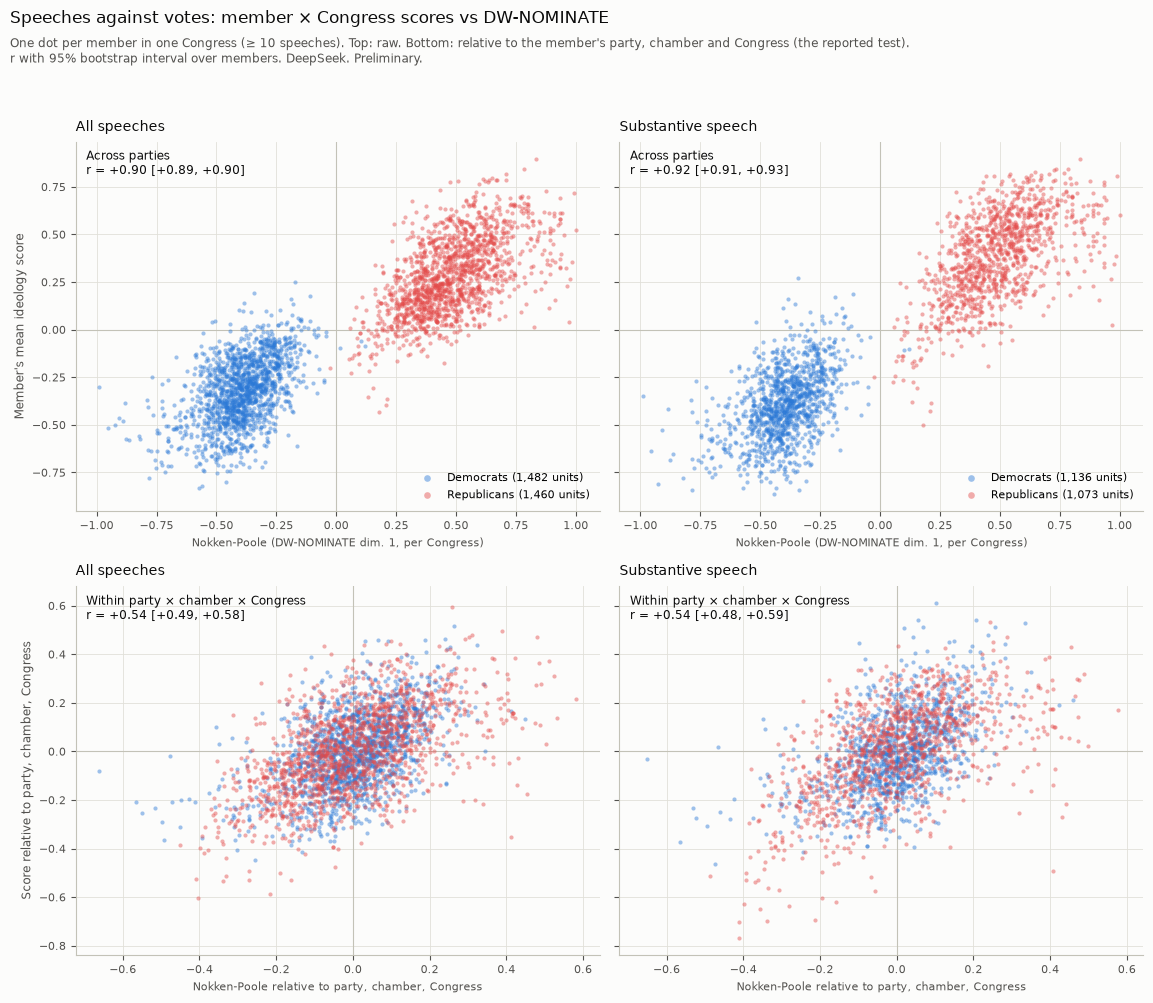

In [6]:
H = VALIDATION_HEADLINE  # member x Congress, >= 10 speeches, Nokken-Poole, within cells (A5)
SETS = {"All speeches": "none", "Substantive speech": "labels"}

validation, units, changes = {}, {}, {}
for name, rule in SETS.items():
    speeches = validation_speeches(everything, rule)
    validation[name] = design_row(speeches, H["unit"], H["benchmark"], H["min_speeches"])
    validation[name]["vs_nominate_dim1"] = design_row(
        speeches, H["unit"], "nominate_dim1", H["min_speeches"]
    )
    units[name] = within_cell(
        unit_table(speeches, H["unit"], H["benchmark"], min_speeches=H["min_speeches"])
    )
    validation[name]["change"] = change_statistics(congress_changes(units[name]))

fig = plot_validation(
    units,
    validation,
    "Speeches against votes: member × Congress scores vs DW-NOMINATE",
    subtitle="One dot per member in one Congress (≥ 10 speeches). Top: raw. Bottom: relative to the member's party, chamber and Congress (the reported test).\nr with 95% bootstrap interval over members. DeepSeek. Preliminary.",
)
save_figure(fig, "findings_validation")
plt.show()

In [7]:
def r_ci(result, stat):
    return f"{result[stat]:+.2f} [{result[f'{stat}_ci_low']:+.2f}, {result[f'{stat}_ci_high']:+.2f}]"


def validation_column(v):
    change = v["change"]
    return {
        "speeches used": f"{v['n_speeches']:,}",
        "member × Congress units (D / R)": f"{v['n_units_D']:,} / {v['n_units_R']:,}",
        "members (D / R)": f"{v['n_members_D']:,} / {v['n_members_R']:,}",
        "within cells, both parties (reported)": r_ci(v, "within_cell_pearson"),
        "within cells, Democrats": r_ci(v, "within_cell_D"),
        "within cells, Republicans": r_ci(v, "within_cell_R"),
        "within cells, House": r_ci(v, "within_cell_H"),
        "within cells, Senate": r_ci(v, "within_cell_S"),
        "within cells, Spearman": r_ci(v, "within_cell_spearman"),
        "within cells, vs nominate_dim1": r_ci(v["vs_nominate_dim1"], "within_cell_pearson"),
        "across parties (overall r)": r_ci(v, "overall_pearson"),
        "party alone": f"{v['party_only_r']:+.2f}",
        "change between Congresses, within cells": r_ci(change, "within_cell_pearson"),
        "  pairs of consecutive Congresses (D / R)": f"{change['n_pairs_D']:,} / {change['n_pairs_R']:,}",
    }


validation_table = pd.DataFrame({name: validation_column(v) for name, v in validation.items()})
validation_table

,All speeches,Substantive speech
speeches used,"82,142","52,458"
member × Congress units (D / R),"1,482 / 1,460","1,136 / 1,073"
members (D / R),404 / 446,315 / 342
"within cells, both parties (reported)","+0.54 [+0.49, +0.58]","+0.54 [+0.48, +0.59]"
"within cells, Democrats","+0.51 [+0.44, +0.57]","+0.50 [+0.42, +0.56]"
"within cells, Republicans","+0.56 [+0.50, +0.62]","+0.57 [+0.48, +0.65]"
"within cells, House","+0.52 [+0.47, +0.56]","+0.52 [+0.46, +0.57]"
"within cells, Senate","+0.58 [+0.49, +0.66]","+0.57 [+0.45, +0.67]"
"within cells, Spearman","+0.52 [+0.48, +0.57]","+0.53 [+0.47, +0.58]"
"within cells, vs nominate_dim1","+0.53 [+0.49, +0.58]","+0.54 [+0.47, +0.60]"


**Reading it.** **The scores order members within their party the way their votes do,
at r = 0.54 in both speech sets**: 0.54 [0.49, 0.58] on all speeches and 0.54 [0.48, 0.59]
on substantive speech, A5's reported number. It holds in each part:

- **By party:** Democrats 0.50–0.51, Republicans 0.56–0.57.
- **By chamber:** House 0.52, Senate 0.57–0.58.
- **By benchmark:** against the career-long `nominate_dim1` it is 0.53–0.54.

**Leaving out procedural and ceremonial speech does not change the validation.** It
changes who qualifies: with all speeches, 2,942 member-Congresses reach 10 speeches,
against 2,209 on substantive speech. It also raises the across-party r from 0.90 to 0.92,
because procedural speeches near 0.0 pull members toward the centre.

**Ignore the across-party r (top row).** Party alone gives r = 0.94 with Nokken-Poole, so
0.90–0.92 mostly restates the party gap. The bottom row is the test.

**What this does not validate:**

- **Movement over time.** Within cells, a member's change between consecutive Congresses
  tracks the change in their votes at only r = 0.14–0.15. The validation supports how
  members are ordered within a Congress, not section 2's movement of parties or members.
- **Infrequent speakers.** At 10 speeches the units are mostly frequent speakers. In A5's
  count, senators make up 45% of the units, against 19% of all member-Congresses, so House
  and Senate are reported apart.

# Part II — Polarization in depth

## 4. Does the picture differ by presidential term?

Each party's mean position per **four-year presidential term** (two Congresses each;
Trump's second term holds 2025 only), then the party gap per term. Section 2 showed each
party furthest out while the other party holds the White House, so the last table asks how
large that opposition effect is once the long-run trend is taken out.

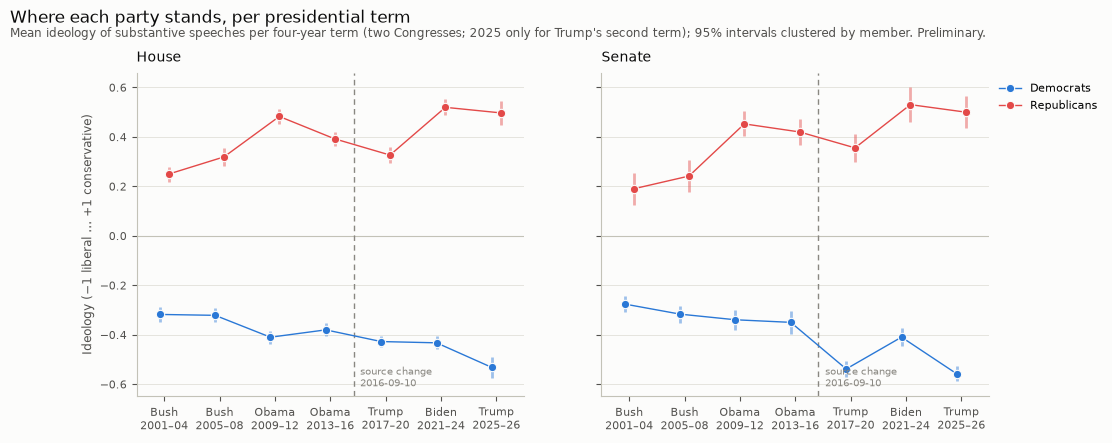

Party gap (R − D) per presidential term, with 95% interval:


chamber,H,S
presidential_term,,
Bush 2001-2004,"+0.57 [+0.52, +0.61]","+0.47 [+0.39, +0.54]"
Bush 2005-2008,"+0.64 [+0.60, +0.69]","+0.56 [+0.48, +0.63]"
Obama 2009-2012,"+0.89 [+0.85, +0.93]","+0.79 [+0.73, +0.86]"
Obama 2013-2016,"+0.77 [+0.73, +0.81]","+0.77 [+0.70, +0.84]"
Trump 2017-2020,"+0.75 [+0.71, +0.79]","+0.89 [+0.83, +0.96]"
Biden 2021-2024,"+0.95 [+0.91, +0.99]","+0.94 [+0.86, +1.02]"
Trump 2025-2026,"+1.03 [+0.96, +1.09]","+1.06 [+0.99, +1.13]"


In [8]:
TERMS = list(dict.fromkeys(df.sort_values("congress_number")["presidential_term"]))


def short_term(term):
    """'Bush 2001-2004' -> 'Bush\n2001–04', so seven terms fit along the axis."""
    name, years = term.rsplit(" ", 1)
    first, last = years.split("-")
    return f"{name}\n{first}–{last[2:]}"


term_cells = cell_means(df, by=("presidential_term", "chamber", "party"))
break_term = df.loc[df["congress_number"] == SOURCE_BREAK_CONGRESS, "presidential_term"].iloc[0]
fig = plot_group_means(
    term_cells,
    "presidential_term",
    "Where each party stands, per presidential term",
    "Ideology (−1 liberal … +1 conservative)",
    subtitle="Mean ideology of substantive speeches per four-year term (two Congresses; 2025 only for Trump's second term); 95% intervals clustered by member. Preliminary.",
    order=TERMS,
    ticklabels={t: short_term(t) for t in TERMS},
    source_break=TERMS.index(break_term) + 0.42,  # September 2016, late in Obama's second term
)
save_figure(fig, "findings_positions_by_term")
plt.show()

term_gaps = party_gap(term_cells, by=("presidential_term", "chamber"))
print("Party gap (R − D) per presidential term, with 95% interval:")
term_gaps.assign(gap_ci=with_ci(term_gaps, "gap")).pivot(
    index="presidential_term", columns="chamber", values="gap_ci"
).loc[TERMS]

**The opposition effect, net of the trend.** Per chamber and party, a speech's
**extremity** (its score toward its party's own side: Republicans as scored, Democrats
sign-flipped, so higher is further out for both) is regressed on the Congress number and on
whether the party is out of the White House. Standard errors are clustered by member.
`in opposition` is how much further out a party sits in opposition than its long-run
trend predicts; `trend per Congress` is that trend.

In [9]:
df = df.assign(extremity=toward_party(df), opposition=df["in_opposition"].astype(float))
TERMS_SHOWN = {"congress_number": "trend per Congress", "opposition": "in opposition"}
opposition_fit = within_cell_ols(
    df, "extremity", ["congress_number", "opposition"], cell=("chamber", "party"), by=("chamber", "party")
)
fit_table(opposition_fit, TERMS_SHOWN)

coef_ci                                      p  \
term                     in opposition       trend per Congress in opposition   
chamber party                                                                   
H       D      +0.004 [-0.012, +0.021]  +0.015 [+0.011, +0.018]          0.61   
        R      +0.110 [+0.087, +0.133]  +0.013 [+0.009, +0.018]         4e-21   
S       D      +0.093 [+0.069, +0.117]  +0.025 [+0.020, +0.030]       1.5e-14   
        R      +0.130 [+0.100, +0.159]  +0.021 [+0.013, +0.029]       6.4e-18   

                                  
term          trend per Congress  
chamber party                     
H       D                1.2e-14  
        R                1.7e-08  
S       D                2.1e-24  
        R                5.5e-08

**Reading it.** **The gap widened in steps across terms**, in both chambers:

| Term | House | Senate |
|---|---|---|
| Bush 2001–2004 | 0.57 | 0.47 |
| Bush 2005–2008 | 0.64 | 0.56 |
| Obama 2009–2012 | 0.89 | 0.79 |
| Obama 2013–2016 | 0.77 | 0.77 |
| Trump 2017–2020 | 0.75 | 0.89 |
| Biden 2021–2024 | 0.95 | 0.94 |
| Trump 2025–2026 | 1.03 | 1.06 |

**The steps come when the White House changes party, and the party that loses it moves:**

- **Republicans** jump right under Obama (House +0.32 → +0.48, Senate +0.24 → +0.45) and
  under Biden (+0.33 → +0.52, +0.36 → +0.53), and ease back under Trump's first term.
- **Senate Democrats** jump left under Trump (−0.35 → −0.54), come back to −0.41 under
  Biden, and reach −0.56 in 2025.
- **House Democrats** move left in steps that barely follow the presidency: −0.32 under
  Bush, −0.38 to −0.41 under Obama, −0.43 under Trump and Biden, −0.53 in 2025.

**Net of the trend, a party sits about 0.1 further out in opposition** in three of four
party-chambers: House Republicans +0.11 [0.09, 0.13], Senate Republicans +0.13 [0.10, 0.16],
Senate Democrats +0.09 [0.07, 0.12]. House Democrats show none (+0.00 [−0.01, +0.02]).
**The long-run outward trend survives the control**: +0.013 to +0.025 per Congress in every
party and chamber, which is 0.16–0.30 over the 12 Congresses.

Two cautions. The White House changed party only four times in the window, so the model
assumes the same opposition effect every time. And 2025 already departs from it:
Republicans stay at about +0.50 while holding the presidency.

## 5. Are newer or younger members further out than their party?

Each speaker's birth year and the number of Congresses they have served (back to 1789, in
either chamber) come from Voteview (A4). Extremity is taken **relative to the mean of the
speaker's own party, chamber and Congress**: 0 means "as far out as their colleagues at the
time", so a group difference is not the 2001–2025 trend in disguise. Groups pool every
Congress, so these plots carry no source break.

Birth year known for 99.91% of substantive speeches.


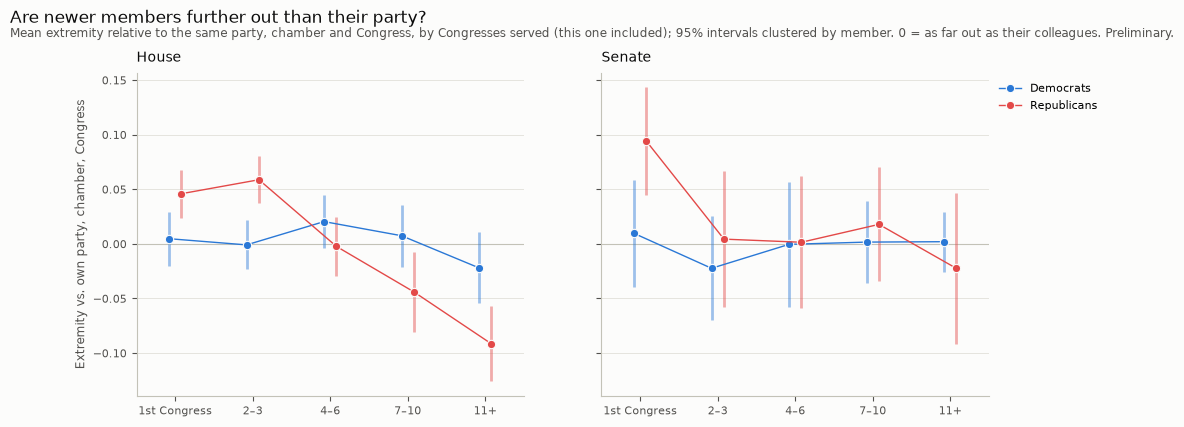

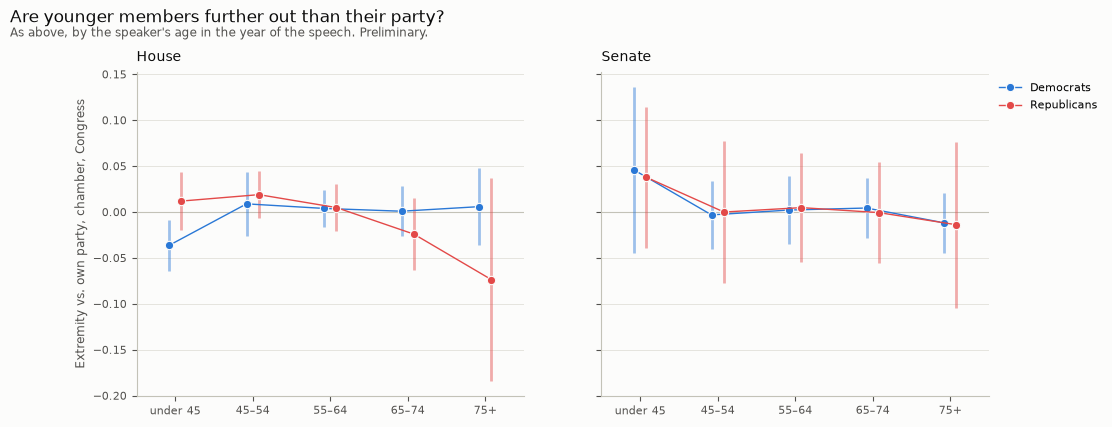

In [10]:
members = add_background(df, member_background())
members["extremity_vs_cell"] = relative_to_cell(members, "extremity")
members["age_decades"] = members["age"] / 10
print(f"Birth year known for {members['born'].notna().mean():.2%} of substantive speeches.")

by_tenure = cell_means(
    members.dropna(subset=["tenure_group"]), "extremity_vs_cell", by=("chamber", "party", "tenure_group")
)
fig = plot_group_means(
    by_tenure,
    "tenure_group",
    "Are newer members further out than their party?",
    "Extremity vs. own party, chamber, Congress",
    subtitle="Mean extremity relative to the same party, chamber and Congress, by Congresses served (this one included); 95% intervals clustered by member. 0 = as far out as their colleagues. Preliminary.",
    order=TENURE_GROUPS,
)
save_figure(fig, "findings_extremity_by_tenure")
plt.show()

by_age = cell_means(
    members.dropna(subset=["age_group"]), "extremity_vs_cell", by=("chamber", "party", "age_group")
)
fig = plot_group_means(
    by_age,
    "age_group",
    "Are younger members further out than their party?",
    "Extremity vs. own party, chamber, Congress",
    subtitle="As above, by the speaker's age in the year of the speech. Preliminary.",
    order=AGE_GROUPS,
)
save_figure(fig, "findings_extremity_by_age")
plt.show()

**Age and tenure together.** Members enter Congress at different ages, so the two can
be separated: extremity regressed on age (per decade) and tenure (per Congress served) at
once, within party, chamber and Congress, clustered by member.

In [11]:
age_tenure = within_cell_ols(members, "extremity", ["age_decades", "tenure"], by=("chamber", "party"))
fit_table(age_tenure, {"age_decades": "per decade of age", "tenure": "per Congress served"})

coef_ci                           \
term               per Congress served        per decade of age   
chamber party                                                     
H       D      -0.005 [-0.009, -0.001]  +0.021 [+0.002, +0.039]   
        R      -0.015 [-0.019, -0.011]  +0.014 [-0.006, +0.034]   
S       D      +0.002 [-0.003, +0.007]  -0.012 [-0.042, +0.018]   
        R      -0.006 [-0.016, +0.004]  +0.014 [-0.031, +0.060]   

                                p                    
term          per Congress served per decade of age  
chamber party                                        
H       D                   0.014             0.029  
        R                 1.1e-13              0.17  
S       D                    0.44              0.44  
        R                    0.21              0.54

**Reading it.** **Newer members are further out than their party — Republicans
only.**

- **House Republicans** in their first Congress sit +0.05 [0.02, 0.07] and in their 2nd–3rd
  +0.06 [0.04, 0.08] beyond their colleagues; with 7–10 Congresses −0.04, with 11+ −0.09
  [−0.13, −0.06]. The newcomer-veteran difference, about 0.15, is close to the House
  Republicans' whole 2001–2016 move (+0.20, section 2).
- **Senate Republicans** in their first Congress sit +0.09 [0.05, 0.14] beyond their
  colleagues; later groups have intervals too wide to read.
- **Democrats** show no tenure pattern: every group is within ±0.02 of their colleagues.

**Younger members are not further out.** Almost every age group sits within ±0.05 of its
colleagues, mostly within its interval. The largest gap, House Republicans over 75 at −0.07,
rests on 37 members and its interval includes 0. The one clear difference runs the other way: House Democrats under
45 are slightly *less* far out (−0.04 [−0.06, −0.01]). The Senate has only 12–18 members
under 45 per party.

**With age held fixed, tenure still matters for House Republicans**: each Congress served
makes them 0.015 [0.011, 0.019] less far out (p ≈ 10⁻¹³). For House Democrats the effect is
a third of that (−0.005), and at the same tenure older House Democrats are slightly further
out (+0.021 per decade). Nothing is clear in the Senate.

So the claim for the team is **"newer Republicans are more radical than their party", not
"younger members are"**. It fits section 2: the Republican party moved further than its
sitting members would on their own, as newer members arrive further out (replacement). Two
cautions: members with long tenure are those who kept winning, and they hold leadership
posts that change what they speak about.

# Part III — Topics

## 6. How much each topic polarized

Policy debates only, since only they carry a topic (labels not yet hand-checked, L4). Each of
the 11 topics gets the fitted change in the party gap from 2001 to 2025, coloured by its
topic block. Single topics are too thin for a line per Congress (as few as 6 speeches in a
party cell), so each gets one trend. The second table sums the topics up into their five
blocks; it picks the blocks for the deep dive in section 7.

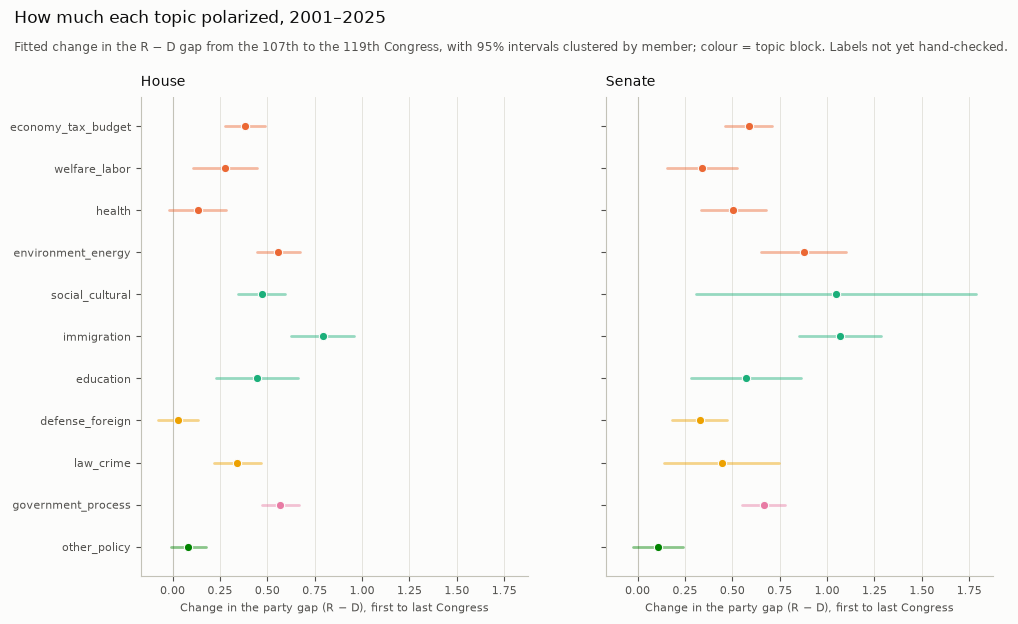

gap_2001                      change  \
chamber                                    H     S                     H   
block            topic                                                     
economic         economy_tax_budget     0.76  0.66  +0.38 [+0.28, +0.49]   
                 welfare_labor          0.72  0.68  +0.28 [+0.11, +0.45]   
                 health                  0.8  0.73  +0.13 [-0.02, +0.28]   
                 environment_energy     0.65  0.53  +0.56 [+0.44, +0.67]   
social_cultural  social_cultural        1.06   0.5  +0.47 [+0.34, +0.59]   
                 immigration            0.67  0.42  +0.79 [+0.63, +0.96]   
                 education              0.51  0.56  +0.45 [+0.23, +0.66]   
security_foreign defense_foreign        0.49   0.4  +0.03 [-0.08, +0.13]   
                 law_crime              0.41  0.29  +0.34 [+0.22, +0.47]   
governance       government_process     0.33  0.32  +0.57 [+0.47, +0.67]   
other            other_policy           0.32  0.31  +0.08 [-0.01, +0.17]   

                                                              n        
chamber                                                 S     H     S  
block            topic                                                 
economic         economy_tax_budget  +0.59 [+0.46, +0.71]  8368  6329  
                 welfare_labor       +0.34 [+0.16, +0.53]  1881  1107  
                 health              +0.51 [+0.33, +0.68]  4259  3702  
                 environment_energy  +0.88 [+0.65, +1.10]  4012  2564  
social_cultural  social_cultural     +1.04 [+0.31, +1.78]  2203  1361  
                 immigration         +1.07 [+0.85, +1.29]  1624  1423  
                 education           +0.57 [+0.28, +0.86]  1066   727  
security_foreign defense_foreign     +0.33 [+0.18, +0.47]  6281  5015  
                 law_crime           +0.44 [+0.14, +0.75]  1472  1075  
governance       government_process  +0.67 [+0.55, +0.78]  2820  4867  
other            other_policy        +0.11 [-0.02, +0.24]  3009  1985

In [12]:
policy = df[df["speech_type"] == "policy_debate"]
block_color = dict(zip(TOPIC_BLOCKS, TOPIC_BLOCK_PALETTE))
topic_order = [t for b in TOPIC_BLOCKS for t in TOPIC_BLOCKS[b]]
topic_trends = gap_trend(policy, by=("chamber", "topic"))
fig = plot_gap_trends(
    topic_trends,
    "topic",
    "How much each topic polarized, 2001–2025",
    subtitle="Fitted change in the R − D gap from the 107th to the 119th Congress, with 95% intervals clustered by member; colour = topic block. Labels not yet hand-checked.",
    order=topic_order,
    colors={t: block_color[BLOCK_OF_TOPIC[t]] for t in topic_order},
)
save_figure(fig, "findings_topic_polarization")
plt.show()

topic_trends.assign(
    block=topic_trends["topic"].map(BLOCK_OF_TOPIC),
    gap_2001=topic_trends["gap_first"].round(2),
    change=span_ci(topic_trends),
).pivot(index=["block", "topic"], columns="chamber", values=["gap_2001", "change", "n"]).reindex(
    [(BLOCK_OF_TOPIC[t], t) for t in topic_order]
)

In [13]:
block_trends = pd.concat(
    [gap_trend(policy, by=("chamber", "topic_block"), congress_range=r).assign(window=w) for w, r in WINDOWS.items()]
)
print("Change in the party gap per topic block, first to last Congress (95% interval), and the gap in 2001:")
block_trends.assign(change=span_ci(block_trends), gap_2001=block_trends["gap_first"].round(2)).pivot(
    index=["chamber", "topic_block"], columns="window", values=["gap_2001", "change"]
).drop(columns=("gap_2001", "2001–2016 (107th–114th)"))

Change in the party gap per topic block, first to last Congress (95% interval), and the gap in 2001:


gap_2001                  change  \
window                   2001–2025 (107th–119th) 2001–2016 (107th–114th)   
chamber topic_block                                                        
H       economic                            0.74    +0.38 [+0.30, +0.46]   
        governance                          0.33    +0.37 [+0.25, +0.49]   
        other                               0.32    +0.13 [+0.03, +0.22]   
        security_foreign                    0.47    -0.02 [-0.12, +0.07]   
        social_cultural                     0.78    +0.34 [+0.21, +0.47]   
S       economic                            0.66    +0.47 [+0.35, +0.59]   
        governance                          0.32    +0.16 [+0.04, +0.28]   
        other                               0.31    +0.07 [-0.06, +0.20]   
        security_foreign                    0.39    +0.12 [-0.02, +0.26]   
        social_cultural                      0.5    +0.60 [+0.18, +1.01]   

                                                  
window                   2001–2025 (107th–119th)  
chamber topic_block                               
H       economic            +0.38 [+0.30, +0.46]  
        governance          +0.57 [+0.47, +0.67]  
        other               +0.08 [-0.01, +0.17]  
        security_foreign    +0.11 [+0.01, +0.20]  
        social_cultural     +0.66 [+0.55, +0.76]  
S       economic            +0.63 [+0.51, +0.75]  
        governance          +0.67 [+0.55, +0.78]  
        other               +0.11 [-0.02, +0.24]  
        security_foreign    +0.34 [+0.20, +0.48]  
        social_cultural     +1.00 [+0.64, +1.35]

**Reading it.** **Immigration polarized most in both chambers**: +0.79 [0.63, 0.96] in
the House and +1.07 [0.85, 1.29] in the Senate. Next come environment and energy (+0.56,
+0.88), government process (+0.57, +0.67), social-cultural issues (+0.47, +1.04, with a
wide Senate interval) and economy, tax and budget (+0.38, +0.59).

**Some topics barely polarized.** Defence and foreign policy hardly moved in the House
(+0.03, interval includes 0) and moderately in the Senate (+0.33). Health in the House
(+0.13) and the residual "other policy" (+0.08, +0.11) also include 0. Topics started apart
too: in 2001 the gap was widest on social-cultural issues in the House (1.06) and on health
and the economy (0.66–0.80), narrowest on government process (0.32–0.33), which then widened
among the most.

**Summed into blocks, three stand out** over 2001–2025: social-cultural (House +0.66,
Senate +1.00), governance (+0.57, +0.67) and economic (+0.38, +0.63). Security and foreign
policy (+0.11, +0.34) and "other" (+0.08, +0.11) widened least. Inside the blocks, the
economic widening comes from environment, energy and the budget, and the social-cultural one
above all from immigration. Section 7 follows these three blocks.

## 7. Deep dive: the three most polarized topic blocks

Social-cultural, economic and governance issues, chosen by the table above. Three views,
per Congress and chamber: how far apart the parties are, **which party moved**, and how much
of the policy debate each block takes up.

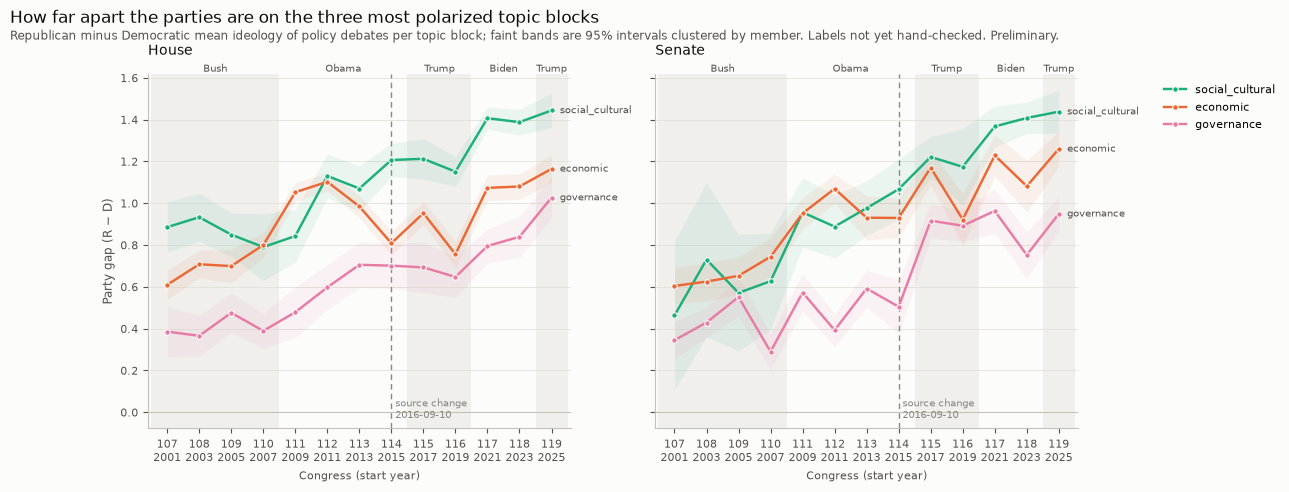

Fewest speeches in any party cell, per block:


topic_block
social_cultural     42
economic           263
governance          45
Name: n, dtype: int64

In [14]:
FOCUS_BLOCKS = ("social_cultural", "economic", "governance")
focus = policy[policy["topic_block"].isin(FOCUS_BLOCKS)]
block_cells = cell_means(focus, by=("congress_number", "chamber", "topic_block", "party"))
block_gaps = party_gap(block_cells, by=("congress_number", "chamber", "topic_block"))
fig = plot_gap_by_group(
    block_gaps,
    "topic_block",
    "How far apart the parties are on the three most polarized topic blocks",
    subtitle="Republican minus Democratic mean ideology of policy debates per topic block; faint bands are 95% intervals clustered by member. Labels not yet hand-checked. Preliminary.",
    order=FOCUS_BLOCKS,
    palette=[block_color[b] for b in FOCUS_BLOCKS],
)
save_figure(fig, "findings_gap_by_topic_block")
plt.show()
print("Fewest speeches in any party cell, per block:")
block_cells.groupby("topic_block")["n"].min().loc[list(FOCUS_BLOCKS)]

**Reading it.** The three blocks widened in different ways:

- **Social-cultural is the most divided block throughout** and widened most: House 0.89 →
  1.44, Senate 0.46 → 1.44. By 2021–2025 it is the widest gap in both chambers.
- **Economic swings with events.** In the House it peaks at 1.10 in 2011 (after the
  financial crisis, the stimulus and health reform), falls to 0.76 in 2019 and reaches 1.16
  in 2025. In the Senate it goes from 0.60 to 1.26.
- **Governance widened late.** In the House it went from 0.39 to about 0.70 by 2013, then
  1.03 in 2025. In the Senate it was flat to 2016 (+0.16), then jumped from 0.50 to 0.92 in
  2017. That jump coincides with both the source change and Trump's first term.

Social-cultural and governance rest on as few as 42–45 speeches in a party cell, so single
Congresses wobble; the trend over the window does not.

**Which party moved on each block?** Each party's mean position per Congress, one row
per block, on one shared scale.

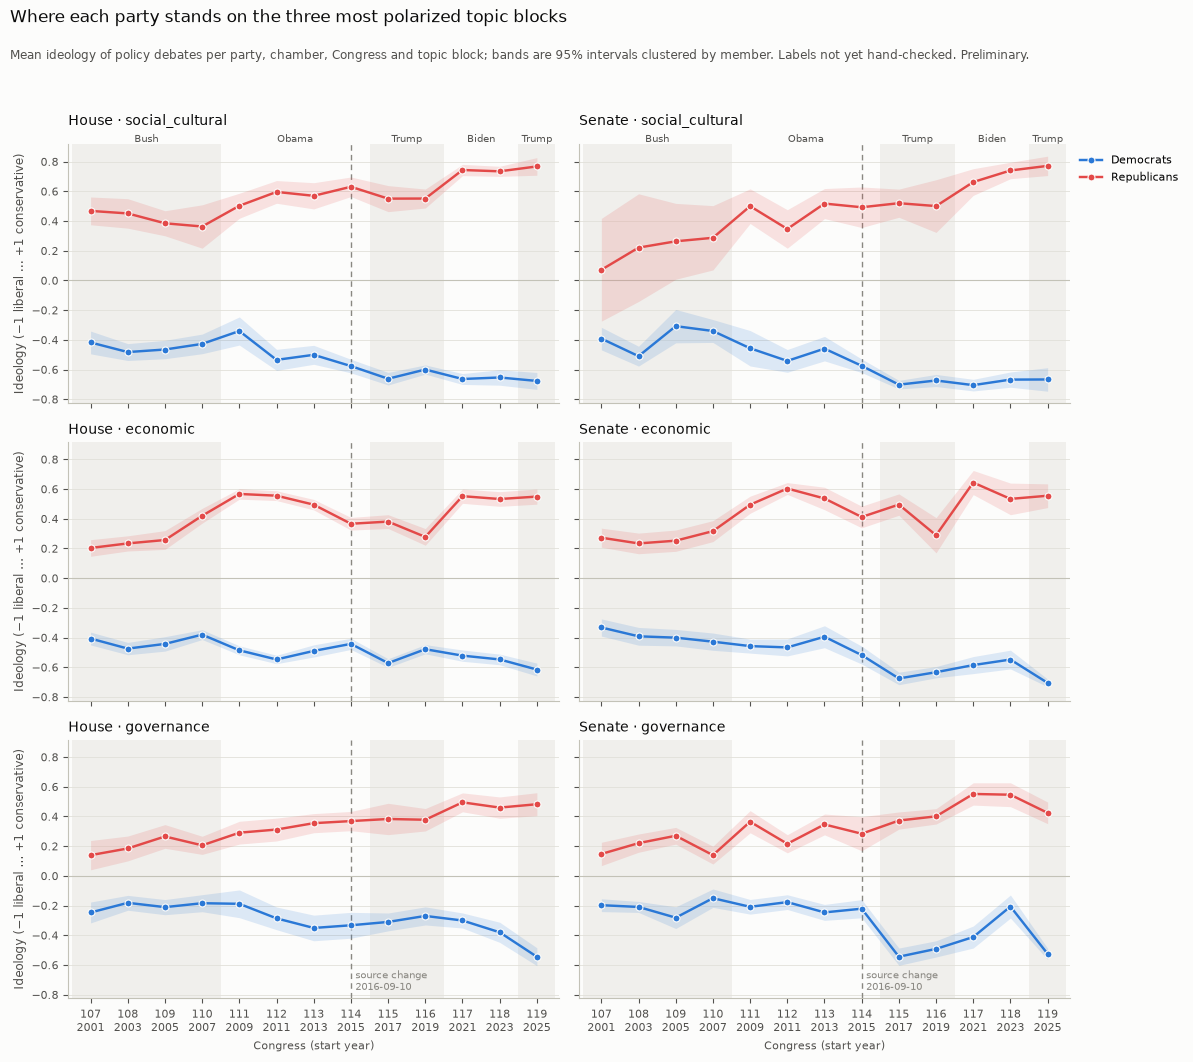

Change in each party's position per block, first to last Congress (95% interval):


window                        2001–2016 (107th–114th) 2001–2025 (107th–119th)
topic_block     chamber party                                                
social_cultural H       D        -0.12 [-0.19, -0.06]    -0.28 [-0.35, -0.22]
                        R        +0.21 [+0.10, +0.32]    +0.37 [+0.28, +0.46]
                S       D        -0.17 [-0.26, -0.08]    -0.37 [-0.45, -0.30]
                        R        +0.43 [+0.02, +0.84]    +0.63 [+0.28, +0.97]
economic        H       D        -0.07 [-0.12, -0.02]    -0.15 [-0.20, -0.11]
                        R        +0.31 [+0.24, +0.37]    +0.23 [+0.16, +0.29]
                S       D        -0.13 [-0.21, -0.05]    -0.35 [-0.42, -0.28]
                        R        +0.34 [+0.25, +0.43]    +0.28 [+0.18, +0.38]
governance      H       D        -0.15 [-0.23, -0.06]    -0.23 [-0.29, -0.17]
                        R        +0.22 [+0.13, +0.31]    +0.34 [+0.26, +0.42]
                S       D        -0.00 [-0.08, +0.08]    -0.31 [-0.39, -0.24]
                        R        +0.16 [+0.08, +0.24]    +0.35 [+0.27, +0.44]

In [15]:
fig = plot_party_positions_by_group(
    block_cells,
    "topic_block",
    "Ideology (−1 liberal … +1 conservative)",
    "Where each party stands on the three most polarized topic blocks",
    subtitle="Mean ideology of policy debates per party, chamber, Congress and topic block; bands are 95% intervals clustered by member. Labels not yet hand-checked. Preliminary.",
    order=FOCUS_BLOCKS,
)
save_figure(fig, "findings_positions_by_topic_block")
plt.show()

block_party_trends = pd.concat(
    [trend(focus, by=("topic_block", "chamber", "party"), congress_range=r).assign(window=w) for w, r in WINDOWS.items()]
)
print("Change in each party's position per block, first to last Congress (95% interval):")
block_party_trends.assign(change=span_ci(block_party_trends)).pivot(
    index=["topic_block", "chamber", "party"], columns="window", values="change"
).loc[list(FOCUS_BLOCKS)]

**Reading it.**

- **Social-cultural: Republicans moved most.** Over 2001–2025 House Republicans moved
  +0.37 [0.28, 0.46] and Democrats −0.28 [−0.35, −0.22]; in the Senate +0.63 [0.28, 0.97]
  against −0.37. In 2023–2025 Republicans sit at +0.73 to +0.77 in both chambers, the
  furthest any party sits on any block. Democrats reached about −0.66 to −0.70 in 2017 and
  have stayed there.
- **Economic: Republicans first, Democrats after 2016.** Up to 2016 Republicans moved far
  more (House +0.31 against −0.07, Senate +0.34 against −0.13). Over the whole window Senate
  Democrats moved further than Republicans (−0.35 against +0.28), and House Democrats
  caught up partly (−0.15 against +0.23). The Republican economic position swings with the
  presidency: House +0.57 in 2009, +0.28 in 2019, +0.55 in 2021.
- **Governance: both parties, about equally.** Over 2001–2025 House Democrats moved −0.23
  and Republicans +0.34; Senate −0.31 and +0.35. Senate Democrats show the clearest
  opposition swing in the data: −0.22 in 2015, −0.54 in 2017, back to −0.21 in 2023 and
  −0.53 in 2025.

So Republicans drove the widening on social-cultural issues, and on the economy up to
2016. On governance, and on the economy after 2016, Democrats moved as much.

**How much of the debate each block takes up.** The share of policy debates per block
and Congress. These are sample shares: every party, chamber and Congress has the same
quota of speeches.

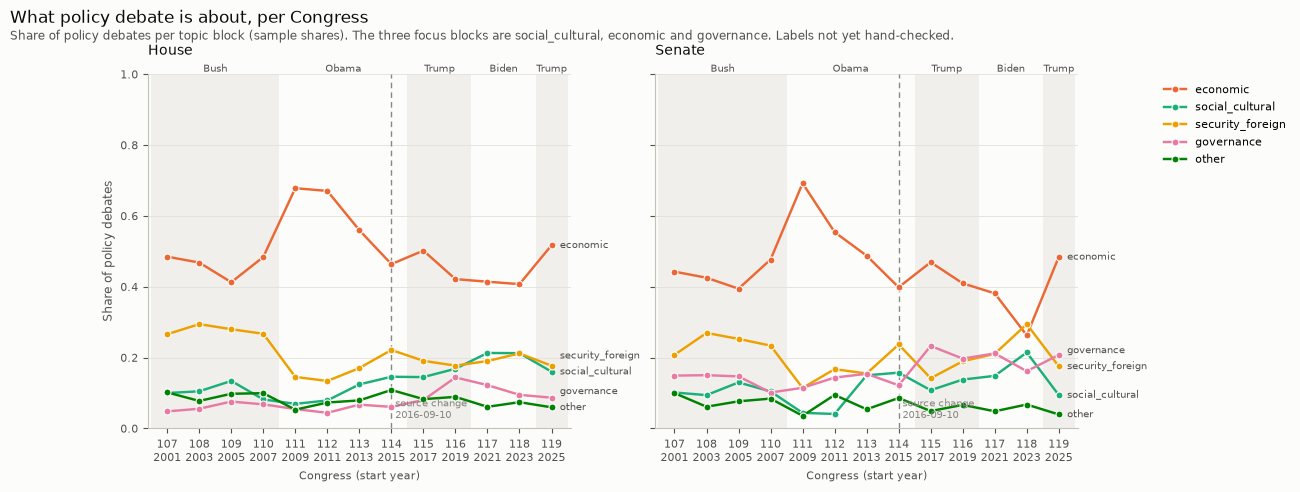

Topic-block shares of policy debate (%), by period:


topic_block                      economic  social_cultural  security_foreign  \
chamber period                                                                 
H       2001–2016 (107th–114th)      52.9             10.5              22.1   
        2017–2025 (115th–119th)      45.1             18.0              18.9   
S       2001–2016 (107th–114th)      48.6             10.2              20.3   
        2017–2025 (115th–119th)      40.5             13.9              20.0   

topic_block                      governance  other  
chamber period                                      
H       2001–2016 (107th–114th)         5.9    8.6  
        2017–2025 (115th–119th)        10.6    7.3  
S       2001–2016 (107th–114th)        13.5    7.3  
        2017–2025 (115th–119th)        20.3    5.4

In [16]:
block_shares = label_shares(policy, ["congress_number", "chamber"], column="topic_block")
fig = plot_label_shares(
    block_shares,
    "What policy debate is about, per Congress",
    subtitle="Share of policy debates per topic block (sample shares). The three focus blocks are social_cultural, economic and governance. Labels not yet hand-checked.",
    order=tuple(TOPIC_BLOCKS),
    column="topic_block",
    palette=TOPIC_BLOCK_PALETTE,
    ylabel="Share of policy debates",
)
save_figure(fig, "findings_topic_block_shares")
plt.show()

periods = policy["congress_number"].le(SOURCE_BREAK_CONGRESS).map(
    {True: "2001–2016 (107th–114th)", False: "2017–2025 (115th–119th)"}
).rename("period")
print("Topic-block shares of policy debate (%), by period:")
(pd.crosstab([policy["chamber"], periods], policy["topic_block"], normalize="index") * 100).round(1)[
    list(TOPIC_BLOCKS)
]

**Reading it.** **The agenda shifted toward the two blocks that widened most.** After
2016, social-cultural issues take 18.0% of House policy debate, up from 10.5% (Senate
10.2% → 13.9%), and governance 10.6%, up from 5.9% (Senate 13.5% → 20.3%). Economic debate
falls from 52.9% to 45.1% (House) and from 48.6% to 40.5% (Senate). It swings with events:
about two-thirds of policy debate in 2009–2010 (financial crisis, stimulus, health reform),
and back to about half in 2025.

**So two things widen the overall gap:** the parties drift apart within each block, and
the debate moves toward the blocks where they are furthest apart. A decomposition with
intervals would say how much each contributes; it is not done here.

# Part IV — Hostility

## 8. Has the tone become more hostile?

Tone is scored from 0 (neutral) to 1 (hostile), on the same substantive speeches. The
tables give each party's trend, and the opposition effect net of that trend, as in
section 4.

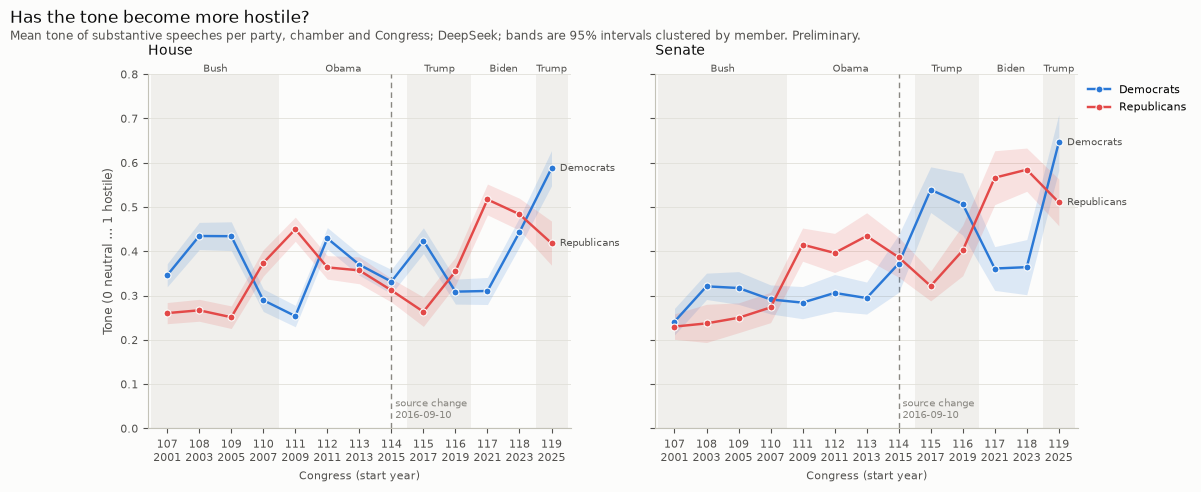

Change in each party's tone, first to last Congress (95% interval):


,window,chamber,party,change,p,n
0,2001–2016 (107th–114th),H,D,"-0.04 [-0.07, -0.00]",0.028,12443
1,2001–2016 (107th–114th),H,R,"+0.10 [+0.07, +0.14]",2.8e-08,11780
2,2001–2016 (107th–114th),S,D,"+0.06 [+0.00, +0.12]",0.041,9924
3,2001–2016 (107th–114th),S,R,"+0.23 [+0.18, +0.28]",6.8e-18,10164
4,2001–2025 (107th–119th),H,D,"+0.08 [+0.03, +0.12]",0.00059,19929
5,2001–2025 (107th–119th),H,R,"+0.17 [+0.13, +0.22]",2.9e-14,18313
6,2001–2025 (107th–119th),S,D,"+0.29 [+0.20, +0.37]",5.2e-11,16792
7,2001–2025 (107th–119th),S,R,"+0.33 [+0.27, +0.38]",3.4e-29,16087


Tone: trend per Congress and the opposition effect, estimated together:


coef_ci                                      p  \
term                     in opposition       trend per Congress in opposition   
chamber party                                                                   
H       D      +0.065 [+0.048, +0.082]  +0.009 [+0.005, +0.013]       3.1e-14   
        R      +0.076 [+0.058, +0.093]  +0.011 [+0.007, +0.015]       8.8e-17   
S       D      +0.141 [+0.106, +0.176]  +0.028 [+0.021, +0.035]       2.1e-15   
        R      +0.099 [+0.078, +0.120]  +0.023 [+0.018, +0.028]       1.6e-20   

                                  
term          trend per Congress  
chamber party                     
H       D                  1e-06  
        R                1.8e-08  
S       D                1.7e-14  
        R                1.3e-22

In [17]:
tone_cells = cell_means(df, value="tone")
fig = plot_party_positions(
    tone_cells,
    "Tone (0 neutral … 1 hostile)",
    "Has the tone become more hostile?",
    subtitle="Mean tone of substantive speeches per party, chamber and Congress; DeepSeek; bands are 95% intervals clustered by member. Preliminary.",
    ylim=(0, 0.8),
)
save_figure(fig, "findings_tone")
plt.show()

tone_trends = pd.concat([trend(df, value="tone", congress_range=r).assign(window=w) for w, r in WINDOWS.items()])
print("Change in each party's tone, first to last Congress (95% interval):")
display(
    tone_trends.assign(change=span_ci(tone_trends), p=tone_trends["p"].map(lambda p: f"{p:.2g}"))[
        ["window", "chamber", "party", "change", "p", "n"]
    ].reset_index(drop=True)
)
tone_opposition = within_cell_ols(
    df, "tone", ["congress_number", "opposition"], cell=("chamber", "party"), by=("chamber", "party")
)
print("Tone: trend per Congress and the opposition effect, estimated together:")
fit_table(tone_opposition, TERMS_SHOWN)

**Reading it.** **Yes: the tone became more hostile in both parties and both
chambers.** Over 2001–2025 it rose by +0.33 [0.27, 0.38] for Senate Republicans, +0.29
[0.20, 0.37] for Senate Democrats, +0.17 for House Republicans and +0.08 for House
Democrats. In 2001 every party-chamber sat at 0.23–0.35; in 2025 Democrats reach 0.59
(House) and 0.65 (Senate), the highest values in the run.

- **Republicans turned harsher first.** Over 2001–2016 Republican tone rose by +0.10 (House)
  and +0.23 (Senate), while Democratic tone barely moved (−0.04, +0.06). The Democratic rise
  comes after 2016.
- **Tone follows opposition even more than ideology does.** Net of the trend, being out of
  the White House adds +0.07 (House Democrats), +0.08 (House Republicans), +0.10 (Senate
  Republicans) and +0.14 (Senate Democrats), all clear. A trend of +0.009 to +0.028 per
  Congress remains on top.
- **The source change is an unlikely cause of the post-2016 rise.** From the 114th to the
  115th Congress, Democratic tone rises (House +0.09, Senate +0.17) while Republican tone
  falls (−0.05, −0.07). A source artifact would have to push the two parties in opposite
  directions.
- **Seen in the table, not tested: House tone also follows control of the House.** House
  Democrats are harsher in every Congress where they are in the House minority (0.33–0.59)
  than in any where they hold it (0.25–0.31). Worth testing for ideology too, where House
  Democrats show no presidency effect (section 4).

One caution: one model scores tone and ideology from the same text, so the two are not
independent measurements.

## Saving the tables

The numbers behind the figures, to `results/metrics/findings_*` (committed). This cell
stays last.

In [18]:
tables = {
    "party_gap": gaps,
    "party_positions": cells,
    "party_trends": party_trends,
    "validation": validation_table.rename_axis("statistic").reset_index(),
    "positions_by_term": term_cells,
    "party_gap_by_term": term_gaps,
    "opposition_effect": opposition_fit,
    "extremity_by_tenure": by_tenure,
    "extremity_by_age": by_age,
    "age_tenure_within_cell": age_tenure,
    "party_gap_by_topic_block": block_gaps,
    "positions_by_topic_block": block_cells,
    "party_trends_by_topic_block": block_party_trends,
    "topic_block_shares": block_shares,
    "gap_trends_by_topic_block": block_trends,
    "gap_trends_by_topic": topic_trends,
    "tone_cells": tone_cells,
    "tone_trends": tone_trends,
    "tone_opposition_effect": tone_opposition,
}
for name, table in tables.items():
    path = METRICS_DIR / f"findings_{name}_{RUN}.csv"
    table.to_csv(path, index=False)
    print(path.relative_to(ROOT))

results/metrics/findings_party_gap_20261018T122536Z.csv
results/metrics/findings_party_positions_20261018T122536Z.csv
results/metrics/findings_party_trends_20261018T122536Z.csv
results/metrics/findings_validation_20261018T122536Z.csv
results/metrics/findings_positions_by_term_20261018T122536Z.csv
results/metrics/findings_party_gap_by_term_20261018T122536Z.csv
results/metrics/findings_opposition_effect_20261018T122536Z.csv
results/metrics/findings_extremity_by_tenure_20261018T122536Z.csv
results/metrics/findings_extremity_by_age_20261018T122536Z.csv
results/metrics/findings_age_tenure_within_cell_20261018T122536Z.csv
results/metrics/findings_party_gap_by_topic_block_20261018T122536Z.csv
results/metrics/findings_positions_by_topic_block_20261018T122536Z.csv
results/metrics/findings_party_trends_by_topic_block_20261018T122536Z.csv
results/metrics/findings_topic_block_shares_20261018T122536Z.csv
results/metrics/findings_gap_trends_by_topic_block_20261018T122536Z.csv
results/metrics/finding